# AI651 PA2 - Question 1 (river proposal figure) and Question 2 (Motion or Memory?)

Driver notebook: all code lives in the public repo https://github.com/RazaTypesCode/DLSTG (branch `PA2`); this notebook clones it and runs it. Nothing uses Google Drive.

**Before running:** Runtime -> Change runtime type -> **T4 GPU**.

**Order matters.** Q2.5 must be committed to the repo before the stress tests (section 5) and Q2.11 before training B, C, D (section 7). Two gate cells check this and stop otherwise.

**If the runtime is recycled**, `/content` is wiped. Run the *Backup* cell (section 11) after each long stage and download the zip; after a reset run section 1, then the *Restore* cell, then continue (finished runs are skipped, unfinished ones resume).

## 1. Setup

In [1]:
import os, torch
REPO = 'https://github.com/RazaTypesCode/DLSTG.git'
BRANCH = 'PA2'
if not os.path.exists('/content/DLSTG'):
    !git clone --branch $BRANCH --single-branch $REPO /content/DLSTG
else:
    !git -C /content/DLSTG pull
os.environ['PA2_RUNS'] = '/content/runs'   # checkpoints + weights (local to this runtime)
os.environ['PA2_DATA'] = '/content/data'   # Moving MNIST download
os.makedirs('/content/runs', exist_ok=True)
print('CUDA available:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU ONLY - switch runtime to T4 GPU')
!git -C /content/DLSTG log --oneline -5

Cloning into '/content/DLSTG'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 47 (delta 3), reused 46 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 1020.14 KiB | 3.41 MiB/s, done.
Resolving deltas: 100% (3/3), done.
CUDA available: True | Tesla T4
6f36a5c (HEAD -> PA2, origin/PA2) Notebooks
5bf44fb First runs


## 2. Question 1 - architecture diagram
The written proposal is `Question1/Q1_river_proposal.tex` in the repo; this cell only draws its architecture figure.

/content/DLSTG/Question1
saved figures/q1_architecture.png


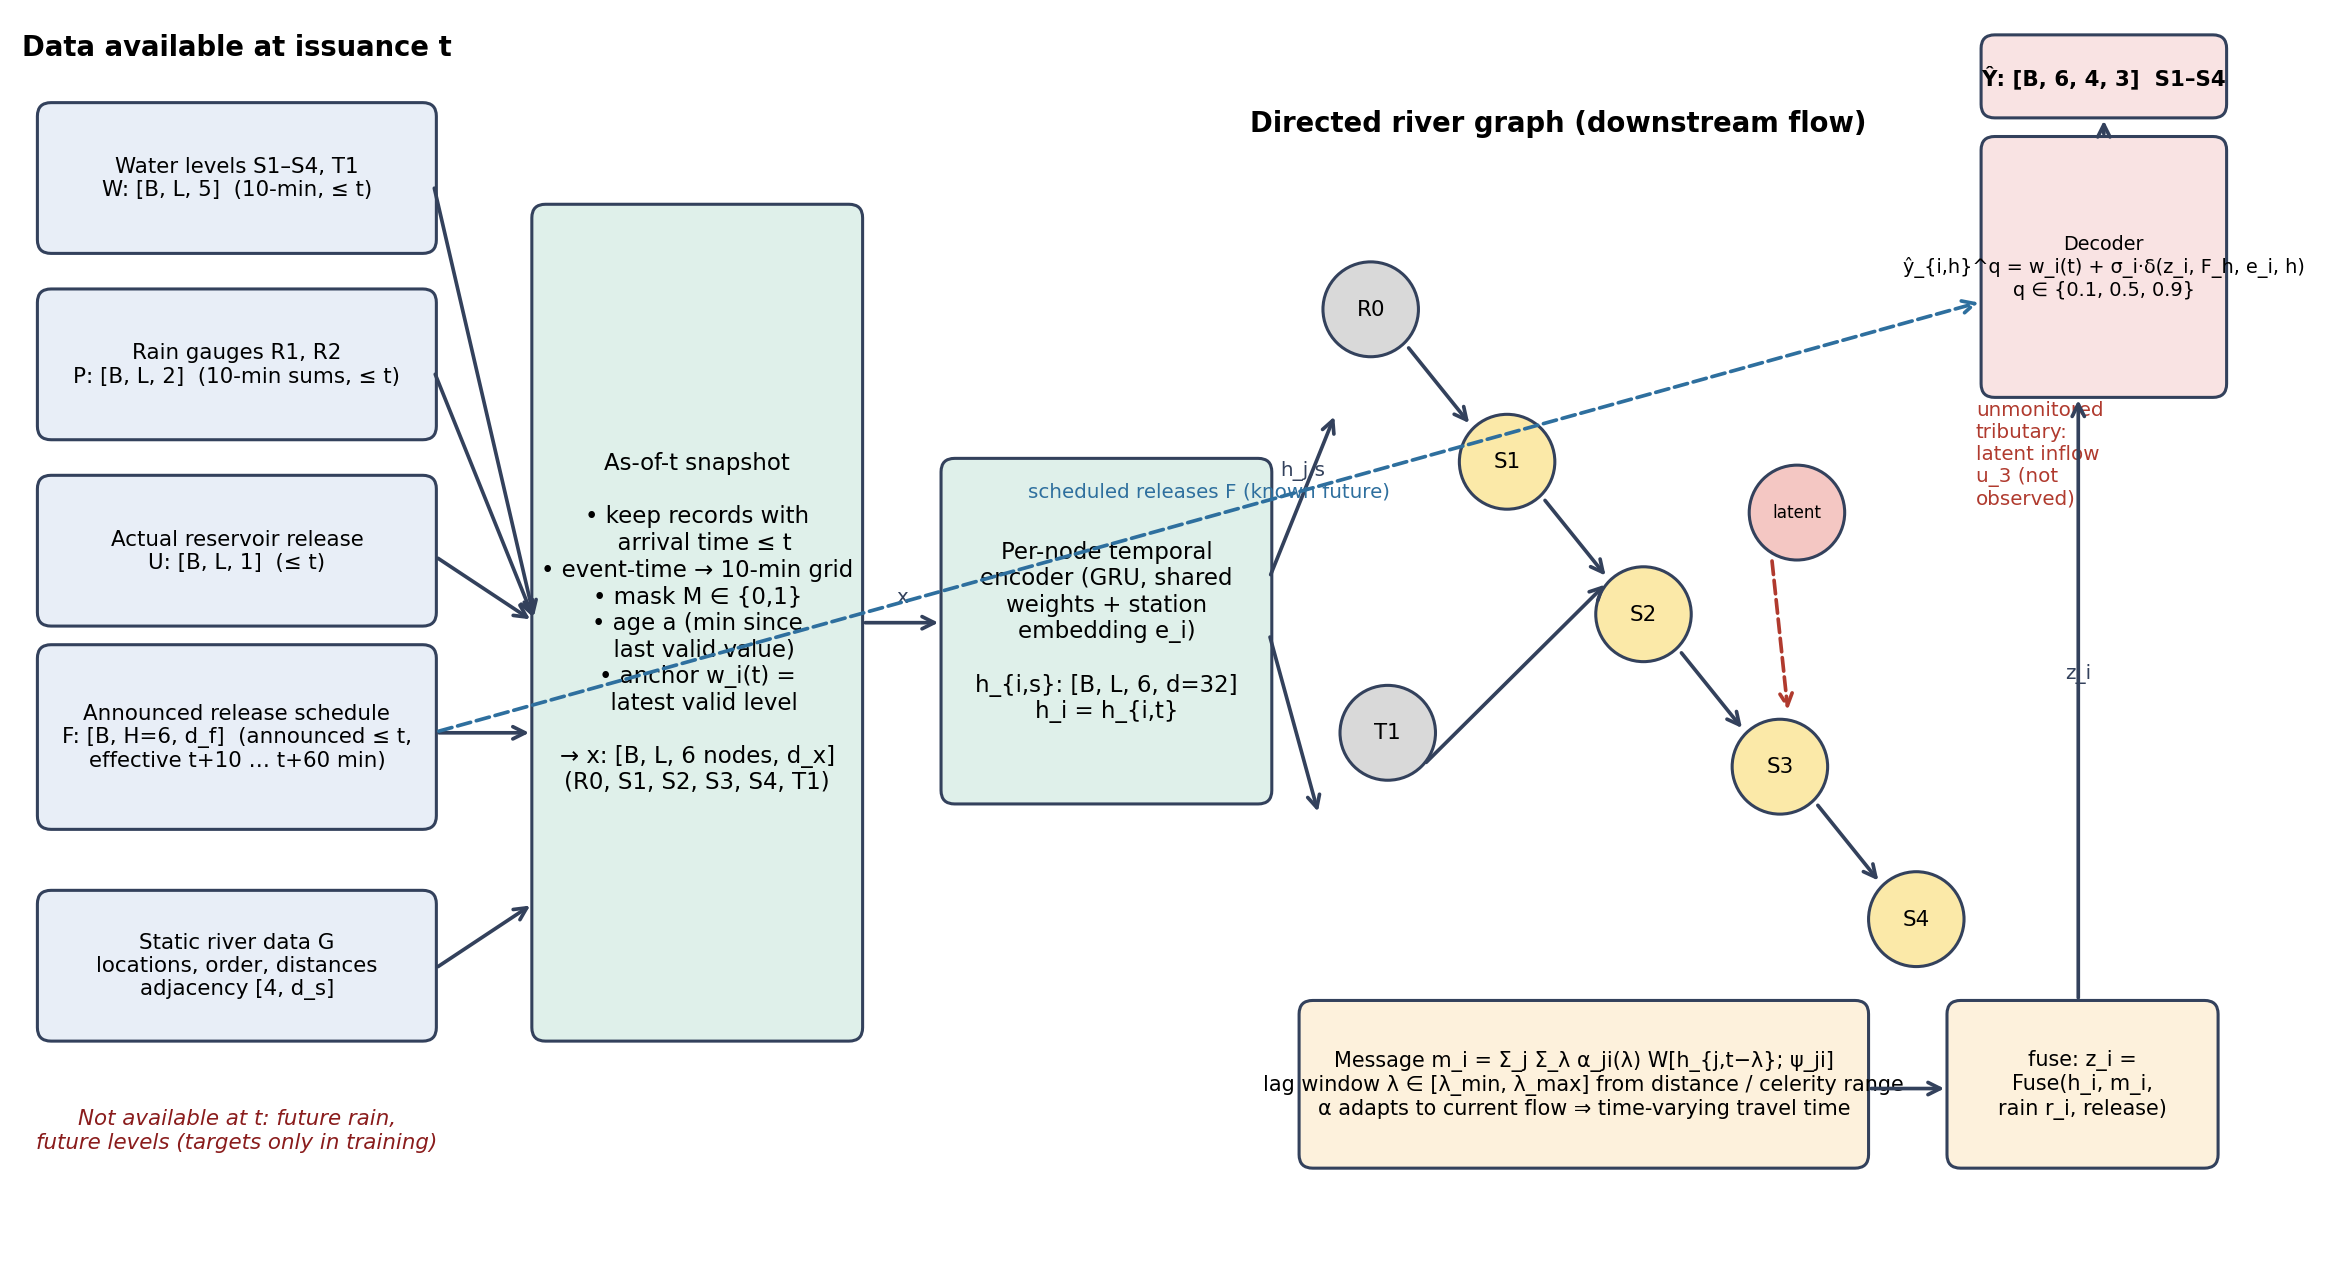

/content/DLSTG/Question2


In [2]:
%cd /content/DLSTG/Question1
!python q1_diagram.py
from IPython.display import Image, display
display(Image('figures/q1_architecture.png'))
%cd /content/DLSTG/Question2

## 3. Question 2 - Table 1 (transform / window checks) and Figure 1 (optical flow)
Table 1 must match the *Expected* values before anything else is trusted.

In [3]:
%cd /content/DLSTG/Question2
!python check_table1.py

/content/DLSTG/Question2
Traceback (most recent call last):
  File "/content/DLSTG/Question2/check_table1.py", line 14, in <module>
    for name, row in rows:
        ^^^^^^^^^
ValueError: too many values to unpack (expected 2)


100% 819M/819M [00:24<00:00, 33.3MB/s]
pixels kept: 103050, median speed: 3.318 px/frame
speed percentiles 10/25/50/75/90/99: [2.14 3.   3.32 3.89 4.12 4.67]
CAPTION: median speed = 3.32 px/frame; 103050 pixels kept from 950 frame pairs.


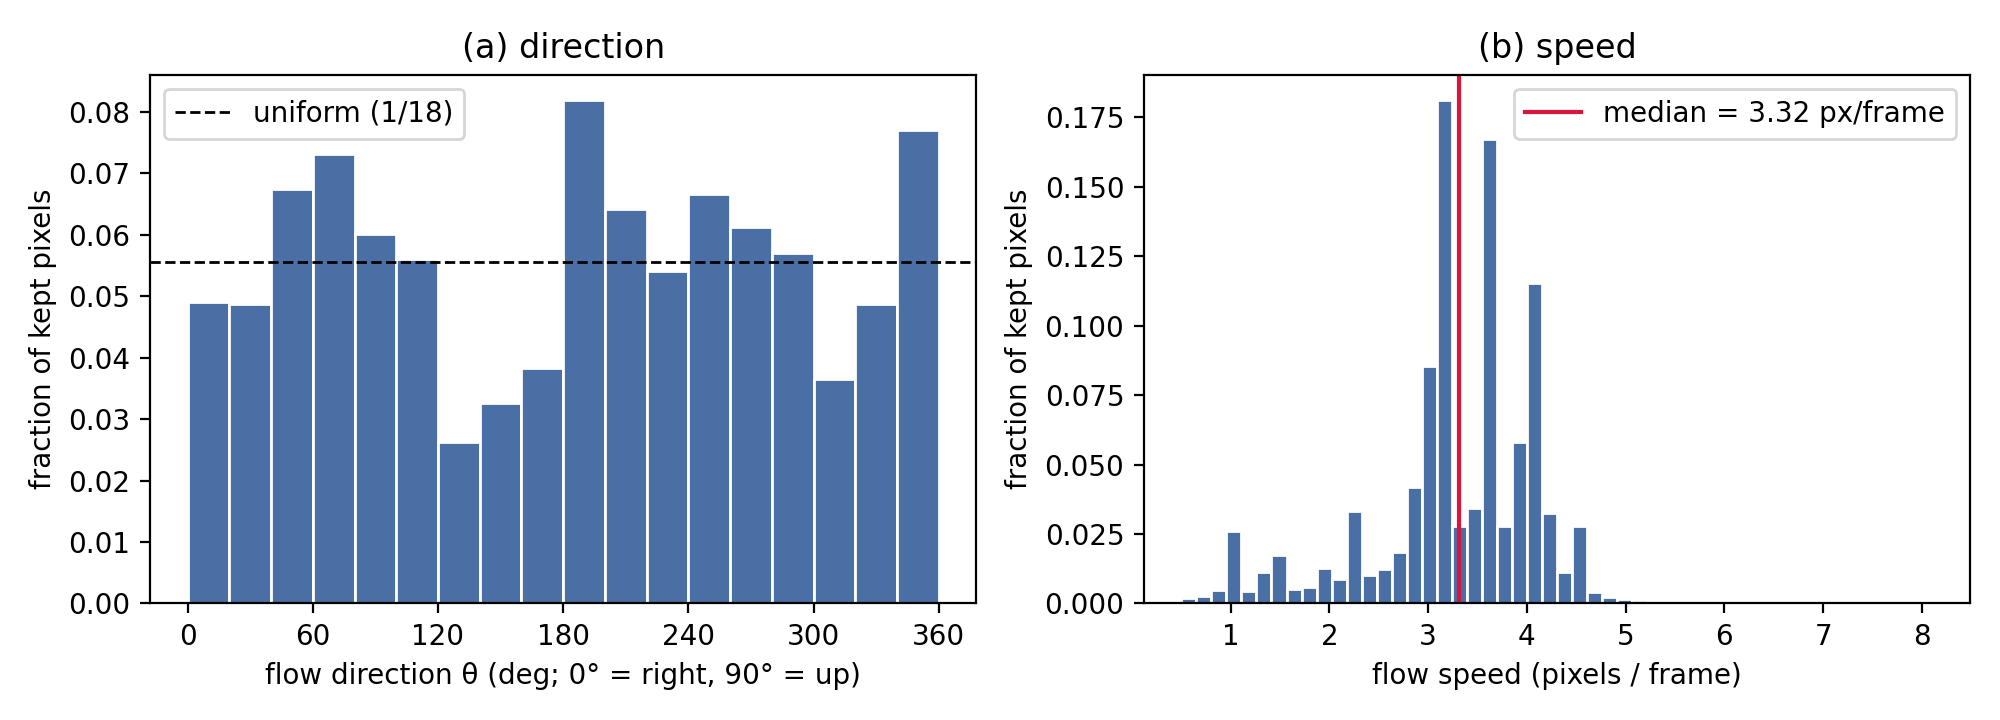

In [4]:
!python fig1_flow.py
from IPython.display import Image, display
display(Image('figures/fig1.png'))

## 4. Train baseline model A (seeds 0 and 1) and run Table 2 / Figure 2

In [5]:
!python train.py --model A --seed 0

A seed 0: params=480784, reach=8px, device=cuda, speed_aug=False, sym_aug=False
{'epoch': 1, 'train_loss': 0.04611336597800255, 'sec': 12.52498197555542, 'val_E5': 0.03931237384676933}
{'epoch': 2, 'train_loss': 0.03966727773845196, 'sec': 9.619536876678467, 'val_E5': 0.038643691688776016}
{'epoch': 3, 'train_loss': 0.038656093776226044, 'sec': 9.74091362953186, 'val_E5': 0.03762385621666908}
{'epoch': 4, 'train_loss': 0.03717958270013332, 'sec': 9.85924768447876, 'val_E5': 0.03595743700861931}
{'epoch': 5, 'train_loss': 0.0352725014090538, 'sec': 9.99130392074585, 'val_E5': 0.03423883765935898}
{'epoch': 6, 'train_loss': 0.03370070127397776, 'sec': 10.107230424880981, 'val_E5': 0.032258596271276474}
{'epoch': 7, 'train_loss': 0.032310121789574625, 'sec': 10.242205619812012, 'val_E5': 0.031162390485405922}
{'epoch': 8, 'train_loss': 0.03125329828262329, 'sec': 10.395216703414917, 'val_E5': 0.030349764972925186}
{'epoch': 9, 'train_loss': 0.030429917052388192, 'sec': 10.547214984893799,

In [6]:
!python train.py --model A --seed 1

A seed 1: params=480784, reach=8px, device=cuda, speed_aug=False, sym_aug=False
{'epoch': 1, 'train_loss': 0.04777123871445656, 'sec': 11.116599321365356, 'val_E5': 0.03936626762151718}
{'epoch': 2, 'train_loss': 0.03996684868633747, 'sec': 10.544330358505249, 'val_E5': 0.03912346437573433}
{'epoch': 3, 'train_loss': 0.03964196665585041, 'sec': 10.711387395858765, 'val_E5': 0.038781892508268356}
{'epoch': 4, 'train_loss': 0.03916129311919212, 'sec': 10.573142290115356, 'val_E5': 0.038025107234716415}
{'epoch': 5, 'train_loss': 0.03749163609743118, 'sec': 10.5051908493042, 'val_E5': 0.03629697114229202}
{'epoch': 6, 'train_loss': 0.03500393842160702, 'sec': 10.476665496826172, 'val_E5': 0.033520787954330444}
{'epoch': 7, 'train_loss': 0.033175209686160084, 'sec': 10.476266145706177, 'val_E5': 0.032228149473667145}
{'epoch': 8, 'train_loss': 0.03184419389814139, 'sec': 10.490716695785522, 'val_E5': 0.031144138425588608}
{'epoch': 9, 'train_loss': 0.03073922123759985, 'sec': 10.5575935840

| Model | MSE_1 | MSE_2 | MSE_3 | MSE_4 | MSE_5 | E(5) | Params |
|---|---|---|---|---|---|---|---|
| A (mean (seed 0, seed 1)) | 0.0172 (0.0174, 0.017) | 0.0205 (0.0207, 0.0203) | 0.0227 (0.0229, 0.0225) | 0.0244 (0.0245, 0.0242) | 0.026 (0.0261, 0.0259) | 0.0221 (0.0223, 0.022) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |
Figure 2 videos (test-relative indices; global = +9000): [0, 6, 7] (first has overlapping digits)
saved figures/fig2.png, results/table2.md


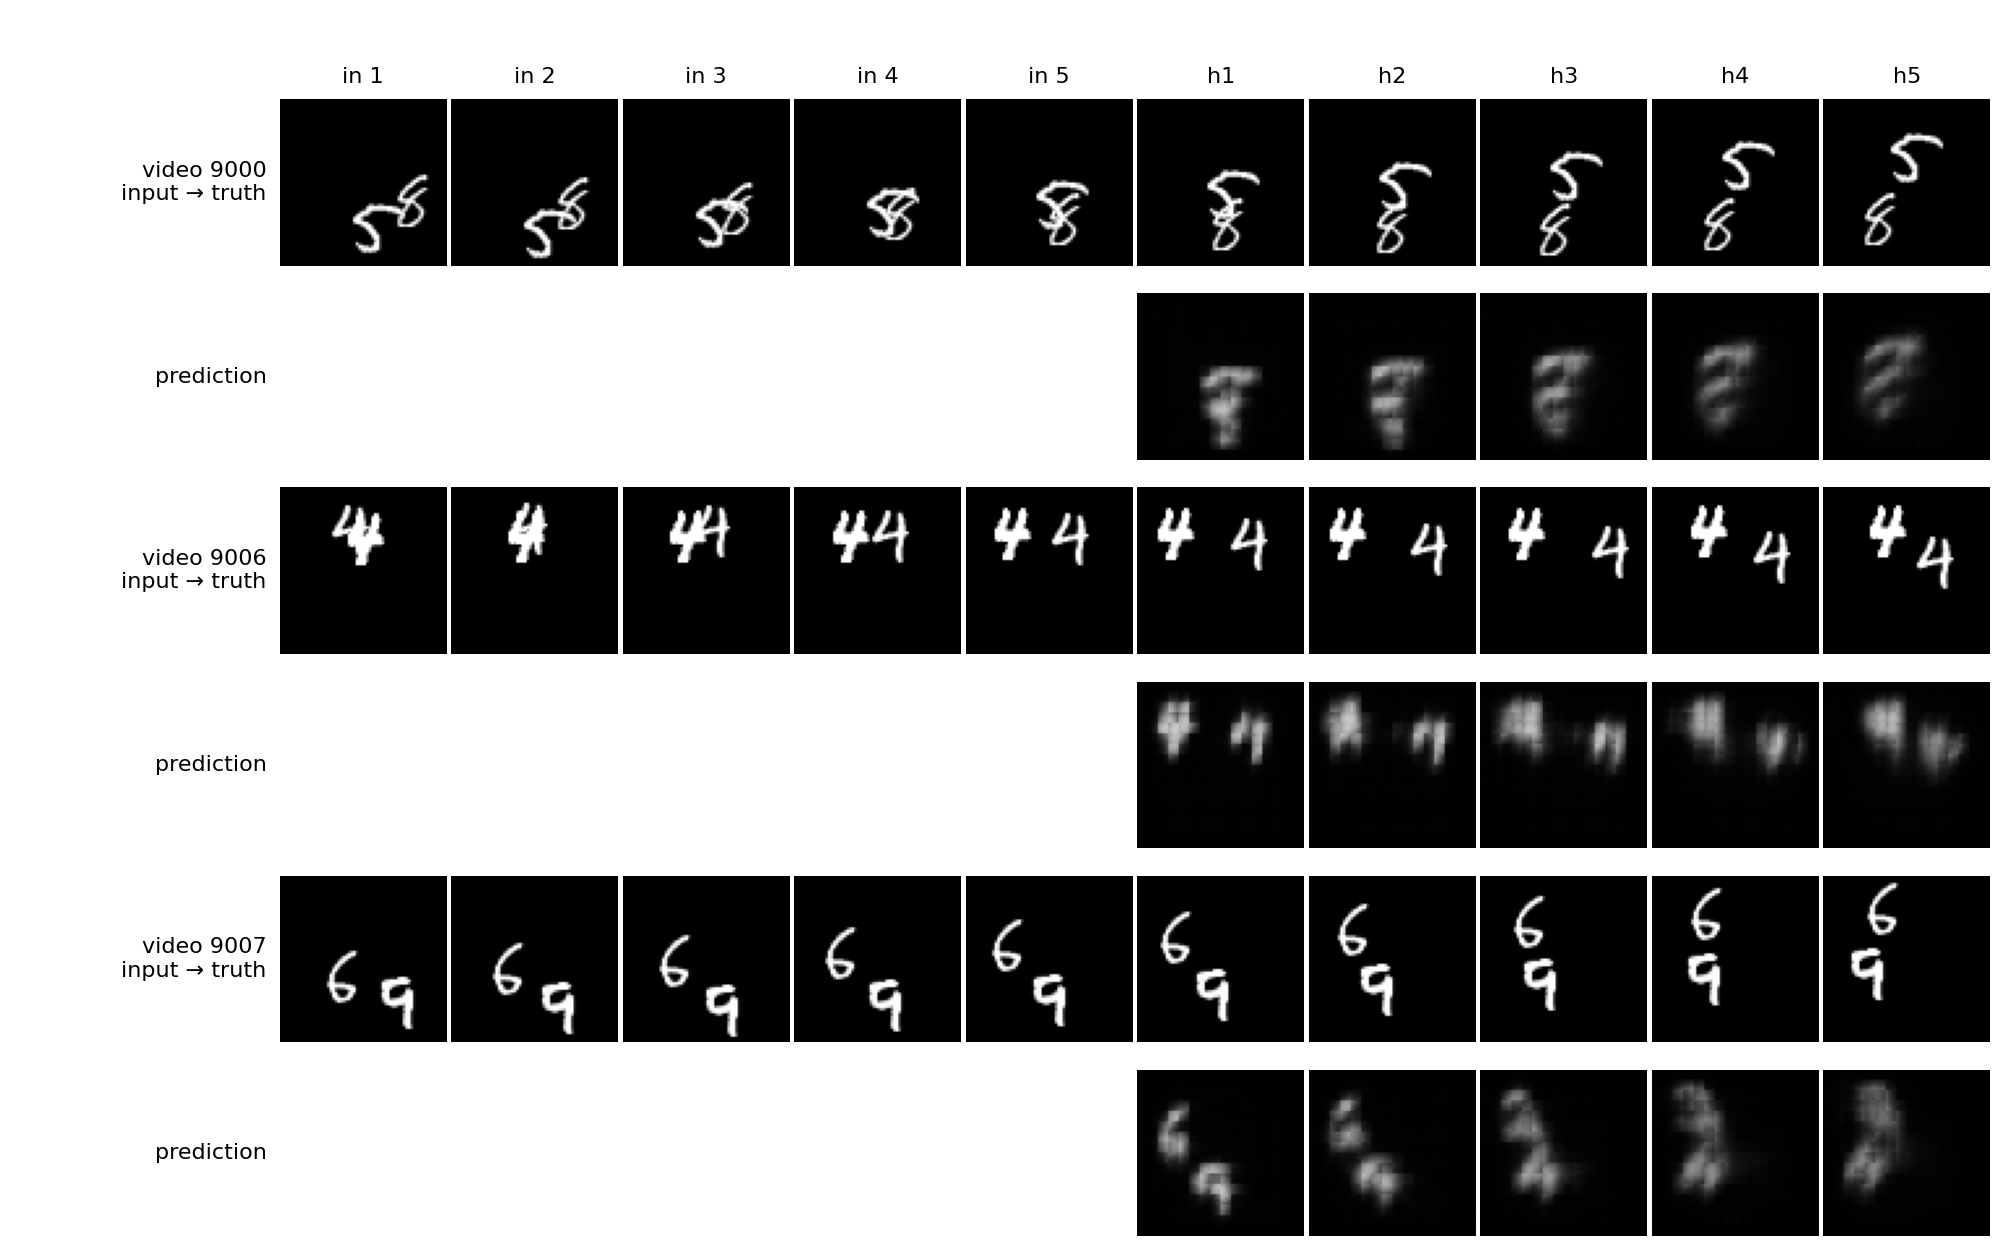

In [7]:
!python stage_A1.py
from IPython.display import Image, display
display(Image('figures/fig2.png'))

### GATE 1 - Q2.5
Write your Q2.5 prediction in `predictions/Q2.5.md`, **commit and push** it, then run this cell. It stops if the file is not in the pushed repo, and prints its commit time.

In [8]:
import subprocess
subprocess.run(['git', '-C', '/content/DLSTG', 'pull'], check=True)
p = 'predictions/Q2.5.md'
t = subprocess.run(['git', '-C', '/content/DLSTG', 'log', '-1', '--format=%cI', '--', p], capture_output=True, text=True).stdout.strip()
assert t, 'Q2.5 not found in the pushed repo: commit and push predictions/Q2.5.md first.'
print('Q2.5 committed at', t)

AssertionError: Q2.5 not found in the pushed repo: commit and push predictions/Q2.5.md first.

## 5. Stress tests on model A: Tables 3-4, Figures 3-5

In [ ]:
%cd /content/DLSTG/Question2
!python stage_A2.py
!cat results/table3.md results/table4.md
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('figures/fig3_*.png')) + ['figures/fig4.png', 'figures/fig5.png']:
    print(f); display(Image(f))

### GATE 2 - Q2.11
Write your Q2.11 prediction (max 3 sentences) in `predictions/Q2.11.md`, **commit and push** it, then run this cell.

In [ ]:
import subprocess
subprocess.run(['git', '-C', '/content/DLSTG', 'pull'], check=True)
p = 'predictions/Q2.11.md'
t = subprocess.run(['git', '-C', '/content/DLSTG', 'log', '-1', '--format=%cI', '--', p], capture_output=True, text=True).stdout.strip()
assert t, 'Q2.11 not found in the pushed repo: commit and push predictions/Q2.11.md first.'
print('Q2.11 committed at', t)

## 6. Models B and C (seeds 0 and 1)

In [ ]:
for m in ('B', 'C'):
    for s in (0, 1):
        !python train.py --model $m --seed $s

## 7. Model D: train both candidates (seed 0), choose on validation only, then seed 1

In [ ]:
!python train.py --model D_p8 --seed 0
!python train.py --model D_dil2 --seed 0

In [ ]:
!python select_D.py
!python train.py --model D --seed 1

## 8. Tables 5-6 and Figure 6 (final model = symmetrised D)

In [ ]:
!python stage_final.py
!cat results/table5.md results/table6.md
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('figures/fig6a_*.png')) + ['figures/fig6b.png']:
    print(f); display(Image(f))

## 9. Hardware and timing record (for the report)

In [ ]:
import json, glob
for f in sorted(glob.glob('/content/runs/*/log.json')):
    d = json.load(open(f))
    print(f"{d['model']:7s} seed {d['seed']}  params {d['params']:>8,}  reach {d['reach_px']:>2} px  {d['mean_epoch_sec']:.1f} s/epoch  [{d['hardware']}]")

## 10. Download the outputs (tables, figures, GIFs)
Download `pa2_outputs.zip` and unzip it at the **root of your repo** (it contains `Question1/figures`, `Question2/results`, `Question2/figures`), then commit (the handout needs the GIFs in the public repo).

In [ ]:
%cd /content/DLSTG
!zip -qr /content/pa2_outputs.zip Question1/figures Question2/results Question2/figures
from google.colab import files
files.download('/content/pa2_outputs.zip')
%cd /content/DLSTG/Question2

## 11. Backup / restore of trained models (no Drive)
Run **Backup** after each long training stage and keep the downloaded zip. After a runtime reset: run section 1, then **Restore**, then continue from where you stopped.

In [ ]:
# BACKUP
!cd /content && zip -qr pa2_runs_backup.zip runs
from google.colab import files
files.download('/content/pa2_runs_backup.zip')

In [ ]:
# RESTORE (after a reset and section 1): choose pa2_runs_backup.zip when prompted
%cd /content
from google.colab import files
up = files.upload()
!unzip -qo /content/pa2_runs_backup.zip -d /content
!ls /content/runs
%cd /content/DLSTG/Question2